<a href="https://colab.research.google.com/github/SNaqvi7/Pneumonia-Detection-Chest-X-rays-using-a-CNN/blob/main/Pneumonia_Detection_from_Chest_X_rays_using_a_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Pneumonia Detection from Chest X-rays By using a CNN**

# Import All Libraries:

Libraries and tools required
Install these libraries in Google Colab or your Python environment.
Library / tool	Purpose
Python ---	Main programming language
--- TensorFlow / Keras	Build, train, and save the CNN
--- NumPy	Numerical operations
--- Matplotlib	Plot accuracy and loss
--- Seaborn	Visualize the confusion matrix
--- scikit-learn	Calculate classification metrics
--- Pillow (PIL)	Open and preprocess X-ray images
--- Flask	Connect the CNN model to the frontend
--- Werkzeug	Handle uploaded files securely
--- HTML, CSS	Create the upload interface

In [13]:
import os
import json
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow.keras import layers, models
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    classification_report
)

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
GPU available: []


In [2]:
import numpy as np
import pandas as pd
import random as rn

# tensorflow
import tensorflow.random as tfr
import tensorflow.keras as keras
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import Dense, Dropout, Flatten
from tensorflow.keras.layers import Conv2D, MaxPool2D, MaxPooling2D, BatchNormalization
from tensorflow.keras import backend as K
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.optimizers import RMSprop, Adam
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

# Chart
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

import seaborn as sns
import glob

from skimage import color, exposure
from sklearn.metrics import classification_report
import os
import cv2

# Setting the same seed for repeatability

seed = 0

np.random.seed(seed)
rn.seed(seed)
tfr.set_seed(seed)

# Display graphs in a Jupyter
%matplotlib inline

print("Imported")


Imported


# UPLOAD DataSet

In [3]:
!kaggle datasets download \
    -d paultimothymooney/chest-xray-pneumonia \
    -p /content/data

!unzip -q /content/data/chest-xray-pneumonia.zip \
    -d /content/data

Dataset URL: https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia
License(s): other
100% 2.29G/2.29G [00:26<00:00, 92.5MB/s]



# Read Data

In [4]:
import numpy as np
import pandas as pd
df = pd.read_csv('pneumonia-detection-on-chest-x-ray-accuracy-92.ipynb')
print(df.head())

Empty DataFrame
Columns: [{"cells":[{"cell_type":"markdown", execution_count:null, metadata:{"papermill":{"duration":0.021334, end_time:"2020-09-09T12:46:46.775048", exception:false, start_time:"2020-09-09T12:46:46.753714", status:"completed"}, tags:[]}, source:["# Pneumonia detection on chest X-ray"]}, {"cell_type":"markdown", execution_count:null.1, metadata:{"papermill":{"duration":0.019427, end_time:"2020-09-09T12:46:46.814423", exception:false.1, start_time:"2020-09-09T12:46:46.794996", status:"completed"}.1, tags:[]}.1, source:["# About Dataset"]}, {"cell_type":"markdown".1, execution_count:null.2, metadata:{"papermill":{"duration":0.020129, end_time:"2020-09-09T12:46:46.854292", exception:false.2, start_time:"2020-09-09T12:46:46.834163", status:"completed"}.2, tags:[]}.2, source:["The dataset contains 5, 863 x-rays (JPEG) divided into two categories (pneumonia / normal).\n", \n, The dataset contains 3 subsets: train, value, test.\n, Due to the fact that the validation kit only c

# Check the dataset folders:

In [5]:
import os

for root, dirs, files in os.walk("/content/data"):
    dirs[:] = [
        d for d in dirs
        if d not in [".ipynb_checkpoints"]]

    if os.path.basename(root).lower() in ["train", "val", "test"]:
        print(root)
        print("Subfolders:", dirs)

/content/data/chest_xray/train
Subfolders: ['PNEUMONIA', 'NORMAL']
/content/data/chest_xray/test
Subfolders: ['PNEUMONIA', 'NORMAL']
/content/data/chest_xray/chest_xray/train
Subfolders: ['PNEUMONIA', 'NORMAL']
/content/data/chest_xray/chest_xray/test
Subfolders: ['PNEUMONIA', 'NORMAL']
/content/data/chest_xray/chest_xray/val
Subfolders: ['PNEUMONIA', 'NORMAL']
/content/data/chest_xray/val
Subfolders: ['PNEUMONIA', 'NORMAL']
/content/data/chest_xray/__MACOSX/chest_xray/train
Subfolders: ['PNEUMONIA', 'NORMAL']
/content/data/chest_xray/__MACOSX/chest_xray/test
Subfolders: ['PNEUMONIA', 'NORMAL']
/content/data/chest_xray/__MACOSX/chest_xray/val
Subfolders: ['PNEUMONIA', 'NORMAL']


chest_xray/
├── train/
│   ├── NORMAL/
│   └── PNEUMONIA/
├── val/
│   ├── NORMAL/
│   └── PNEUMONIA/
└── test/
    ├── NORMAL/
    └── PNEUMONIA/

In [6]:
import os

DATA_DIR = "/content/data/chest_xray"

if not os.path.isdir(DATA_DIR):
    candidates = []

    for root, dirs, files in os.walk("/content/data"):
        if (os.path.isdir(os.path.join(root, "train", "NORMAL"))
            and os.path.isdir(os.path.join(root, "train", "PNEUMONIA"))
            and os.path.isdir(os.path.join(root, "test", "NORMAL"))
            and os.path.isdir(os.path.join(root, "test", "PNEUMONIA"))):
            candidates.append(root)

    if candidates:
        DATA_DIR = candidates[0]

print("Dataset path:", DATA_DIR)
print("Training folder exists:", os.path.isdir(os.path.join(DATA_DIR, "train")))

Dataset path: /content/data/chest_xray
Training folder exists: True


# Install and import the ML libraries

In [7]:
!pip install -q tensorflow scikit-learn seaborn matplotlib pillow

# Load and preprocess the images

In [8]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(os.path.join(DATA_DIR, "train"),
    class_names=["NORMAL", "PNEUMONIA"],
    validation_split=0.15,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary")

val_ds = tf.keras.utils.image_dataset_from_directory(os.path.join(DATA_DIR, "train"),
    class_names=["NORMAL", "PNEUMONIA"],
    validation_split=0.15,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False)

test_ds = tf.keras.utils.image_dataset_from_directory( os.path.join(DATA_DIR, "test"),
    class_names=["NORMAL", "PNEUMONIA"],
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False)

print("Class names:", train_ds.class_names)

Found 5216 files belonging to 2 classes.
Using 4434 files for training.
Found 5216 files belonging to 2 classes.
Using 782 files for validation.
Found 624 files belonging to 2 classes.
Class names: ['NORMAL', 'PNEUMONIA']


0 = NORMAL
1 = PNEUMONIA

# View sample images

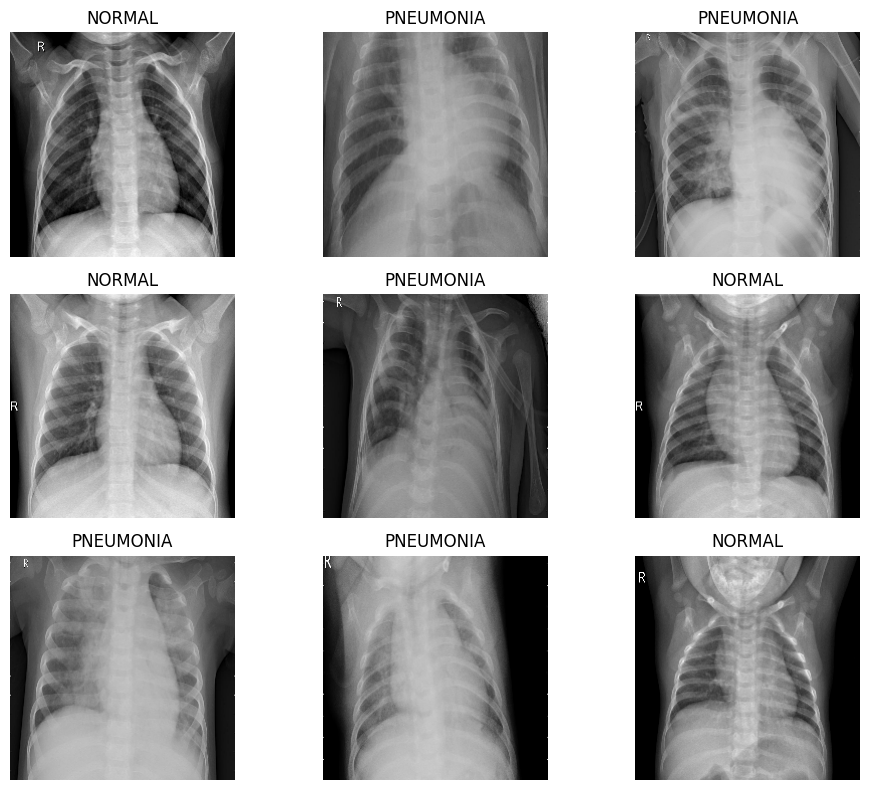

In [9]:
plt.figure(figsize=(10, 8))

for images, labels in train_ds.take(1):
    for i in range(min(9, len(images))):
        ax = plt.subplot(3, 3, i + 1)

        plt.imshow(images[i].numpy().astype("uint8"))

        label = int(labels[i].numpy()[0])
        plt.title(train_ds.class_names[label])
        plt.axis("off")

plt.tight_layout()
plt.show()

# Optimize data loading

In [10]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

print("Image datasets are ready.")

Image datasets are ready.


# Build the CNN architecture:
A CNN learns visual patterns using convolutional layers. Early layers learn simple edges and textures, while deeper layers can learn more complex patterns.

Model Uses:
- Conv2D — extracts image features.
- MaxPooling2D — reduces spatial dimensions.
- GlobalAveragePooling2D — summarizes the learned features.
- Dropout — helps reduce overfitting.
- Dense(1, sigmoid) — produces a binary classification score.

In [11]:
augmentation = models.Sequential([layers.RandomRotation(0.03), layers.RandomTranslation(0.03, 0.03),layers.RandomZoom(0.05)], name="augmentation")

model = models.Sequential([layers.Input(shape=(224, 224, 3)),augmentation,
    layers.Rescaling(1.0 / 255),

    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(128, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(256, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),

    layers.GlobalAveragePooling2D(), layers.Dense(128, activation="relu"), layers.Dropout(0.5), layers.Dense(1, activation="sigmoid")])

model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="binary_crossentropy",
    metrics=["accuracy"])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 421,441 (1.61 MB)

 Trainable params: 421,441 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

So The augmentation layers operate during training. The rescaling layer normalizes image pixels to the range 0–1. During prediction, the model receives the same 224 × 224 image format.

# Train the CNN:
i will train for up to 15 epochs initially. An epoch means one pass through the training dataset

In [12]:
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        "/content/best_pneumonia_model.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        verbose=1)]

history = model.fit(train_ds, validation_data=val_ds, epochs=15, callbacks=callbacks)

Epoch 1/15
139/139 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.7251 - loss: 0.6105
Epoch 1: val_loss improved from None to 0.31231, saving model to /content/best_pneumonia_model.keras

Epoch 1: finished saving model to /content/best_pneumonia_model.keras
139/139 ━━━━━━━━━━━━━━━━━━━━ 492s 4s/step - accuracy: 0.7393 - loss: 0.5916 - val_accuracy: 1.0000 - val_loss: 0.3123 - learning_rate: 1.0000e-04
Epoch 2/15
139/139 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.7346 - loss: 0.5841
Epoch 2: val_loss did not improve from 0.31231
139/139 ━━━━━━━━━━━━━━━━━━━━ 486s 3s/step - accuracy: 0.7391 - loss: 0.5652 - val_accuracy: 0.9399 - val_loss: 0.3523 - learning_rate: 1.0000e-04
Epoch 3/15
139/139 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.7258 - loss: 0.5284
Epoch 3: val_loss improved from 0.31231 to 0.26797, saving model to /content/best_pneumonia_model.keras

Epoch 3: finished saving model to /content/best_pneumonia_model.keras
139/139 ━━━━━━━━━━━━━━━━━━━━ 552s 4s/step - accuracy: 0.736

# Plot accuracy and loss

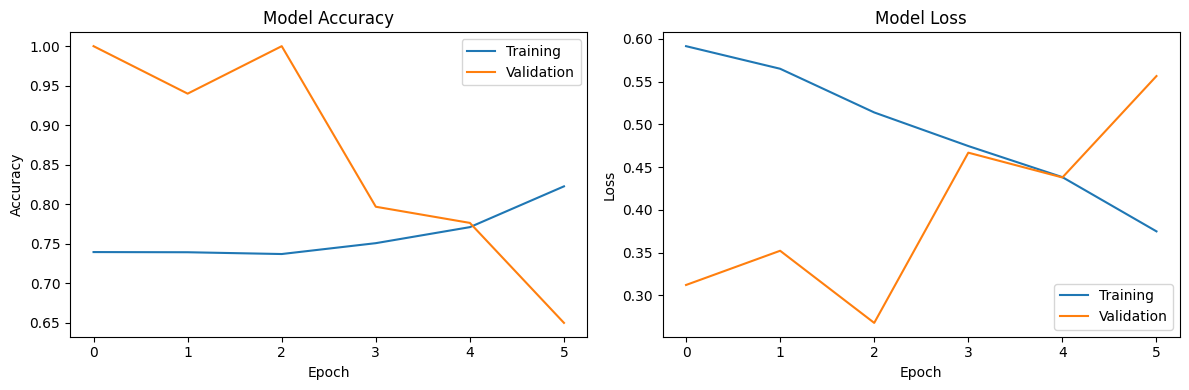

In [14]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

# Evaluate the CNN on test images

In [15]:
model = tf.keras.models.load_model(
    "/content/best_pneumonia_model.keras")

# calculate the metrics:

In [16]:
y_true = []
y_prob = []

for images, labels in test_ds:
    probs = model.predict(images, verbose=0).ravel()

    y_prob.extend(probs)
    y_true.extend(labels.numpy().ravel().astype(int))

y_true = np.array(y_true)
y_prob = np.array(y_prob)

THRESHOLD = 0.5
y_pred = (y_prob >= THRESHOLD).astype(int)

print("Accuracy:", round(accuracy_score(y_true, y_pred), 4))

print("Precision:",round(precision_score(y_true, y_pred, zero_division=0), 4))

print("Recall:",round(recall_score(y_true, y_pred, zero_division=0), 4))

print("\nFull classification report:")
print(classification_report(y_true, y_pred, labels=[0, 1], target_names=["NORMAL", "PNEUMONIA"], zero_division=0))

Accuracy: 0.6282
Precision: 0.6274
Recall: 0.9974

Full classification report:
              precision    recall  f1-score   support

      NORMAL       0.75      0.01      0.03       234
   PNEUMONIA       0.63      1.00      0.77       390

    accuracy                           0.63       624
   macro avg       0.69      0.51      0.40       624
weighted avg       0.67      0.63      0.49       624



# Display the confusion matrix:

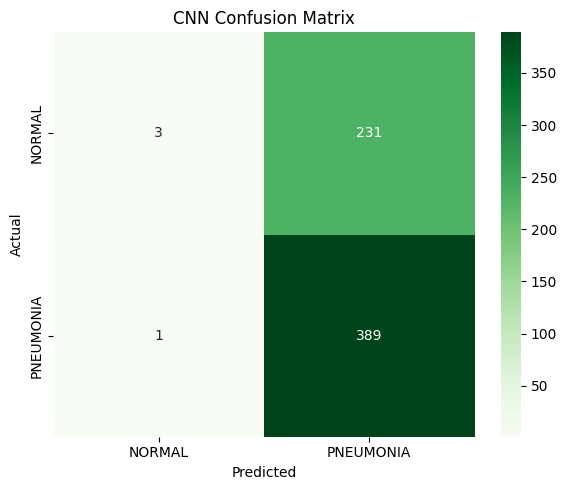

In [19]:
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

plt.figure(figsize=(6, 5))

sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", xticklabels=["NORMAL", "PNEUMONIA"], yticklabels=["NORMAL", "PNEUMONIA"])

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("CNN Confusion Matrix")
plt.tight_layout()
plt.show()

# Test one X-ray image:

Saving predict-pneumonia-X-Ray.jpg to predict-pneumonia-X-Ray.jpg
Saving x-ray image.avif to x-ray image.avif


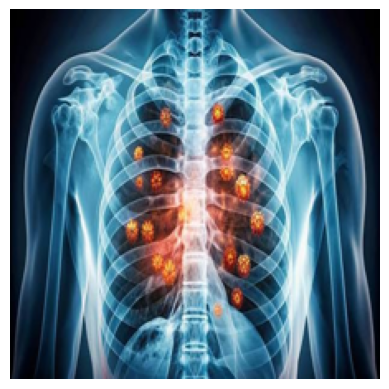

Predicted class: NORMAL
Model score: 53.18%


In [20]:
from google.colab import files
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

uploaded = files.upload()

filename = next(iter(uploaded))

img = Image.open(filename).convert("RGB")
img = img.resize((224, 224))

image_array = np.array(img, dtype=np.float32)
image_array = np.expand_dims(image_array, axis=0)

probability = float(model.predict(image_array, verbose=0)[0][0])

if probability >= 0.5:
    prediction = "PNEUMONIA"
    score = probability * 100
else:
    prediction = "NORMAL"
    score = (1 - probability) * 100

plt.imshow(img)
plt.axis("off")
plt.show()

print("Predicted class:", prediction)
print(f"Model score: {score:.2f}%")

# Save and download the trained model:

In [17]:
import json
from google.colab import files

model.save("/content/pneumonia_cnn.keras")

with open("/content/class_names.json", "w") as f:
    json.dump(["NORMAL", "PNEUMONIA"], f)

files.download("/content/pneumonia_cnn.keras")
files.download("/content/class_names.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Check List:

What comes next?
Training checklist
[ ] Opened Google Colab
[ ] Downloaded and located the dataset
[ ] Loaded and visualized images
[ ] Built and trained the CNN
[ ] Calculated evaluation metrics
[ ] Saved and tested the model
0 of 6 completed